In [141]:
# set working directory to the script's directory
import os

# Set your desired path
# os.chdir("/workspaces/microsplit_DOL")
os.chdir("/Users/valentingoupille/Desktop/microsplit_DOL")

# Check if it worked
print("Current working directory:", os.getcwd())

os.listdir()


# These imports and path modifications are only necessary for development
import importlib

import os
import sys

module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

Current working directory: /Users/valentingoupille/Desktop/microsplit_DOL


In [142]:
!pip install KDEpy


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [143]:
import pandas as pd
import scanpy as sc
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sps

import BacSC2.util_probe as up
import BacSC2.util as ut
import BacSC2.NB_est as nb
import BacSC2.countsplit as cs
from BacSC2 import scDEED as scd  # ← Maintenant ça marche !
import BacSC2.clustering_opt as co

import warnings

warnings.filterwarnings("ignore")

# BacSC general pipeline - Tutorial

This tutorial covers how to use the BacSC pipeline to perform automated analysis of (bacterial) single-cell data. In this tutorial, we analyze B.subtilis grown in minimal media, that were sequenced with the ProBac method (McNulty et al., 2023).

The easiest way to apply the same pipeline to your data is to copy this notebook and perform every step on your dataset

## Preprocessing
### Read data

In [144]:
# Adjust the data path and filename based on your folder structure
data_path = "code/27"
data_all = sc.read(data_path + "/final_adata_filtered.h5ad")
data_all

AnnData object with n_obs × n_vars = 2913 × 5509
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group'
    var: 'feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10

In [145]:
sc.pp.calculate_qc_metrics(data_all, inplace=True, log1p=True)

In [146]:
data_all.var.head()

,feature_id,gene_id,feature_type,Accession,Begin,End,Chromosome,Orientation,Name,Symbol,...,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct
gene_id,,,,,,,,,,,,,,,,,,,,,
QLH64-00030,gene-QLH64_00030,QLH64-00030,Gene Expression,CP125961.1,5894,9346,unknown,plus,exodeoxyribonuclease V subunit gamma,recC,...,94.747683,158,5.068904,156,True,False,True,False,False,False
QLH64-00035,gene-QLH64_00035,QLH64-00035,Gene Expression,CP125961.1,9343,13032,unknown,plus,exodeoxyribonuclease V subunit beta,recB,...,96.120838,116,4.762174,119,True,False,True,False,False,False
QLH64-00040,gene-QLH64_00040,QLH64-00040,Gene Expression,CP125961.1,13029,15125,unknown,plus,exodeoxyribonuclease V subunit alpha,recD,...,96.326811,111,4.718499,109,True,False,False,False,False,False
QLH64-00045,gene-QLH64_00045,QLH64-00045,Gene Expression,CP125961.1,15265,15840,chromosome,plus,YfiR family protein,NaN,...,98.077583,56,4.043051,58,False,False,False,False,False,False
QLH64-00050,gene-QLH64_00050,QLH64-00050,Gene Expression,CP125961.1,15837,17105,chromosome,plus,diguanylate cyclase,NaN,...,98.489530,45,3.828641,44,True,False,False,False,False,False


In [147]:
data_all.var[
    "n_cells_by_counts"
].describe()  # est le nombre de ceelules dans lequel on detecte ce gene

count    5509.000000
mean      198.706843
std       353.717731
min         4.000000
25%        28.000000
50%        70.000000
75%       191.000000
max      2852.000000
Name: n_cells_by_counts, dtype: float64

In [148]:
data_all.var[
    "mean_counts"
].describe()  # mean_counts est la moyenne du nombre brut de comptes (UMIs) par gène, calculée sur toutes les cellules, sans transformation log ni normalisation.

count    5509.000000
mean        0.101548
std         0.334452
min         0.001373
25%         0.009612
50%         0.024717
75%         0.069001
max         8.921730
Name: mean_counts, dtype: float64

In [149]:
# %%
data_all.var

# Remplacer les noms de gènes dans l'objet AnnData
data_all.var["original_gene_ids"] = (
    data_all.var_names
)  # Optionnel : garder les anciens noms
data_all.var_names = data_all.var["final_gene_name"]

print("✅ Les noms de gènes ont été remplacés avec succès par 'final_gene_name'.")

data_all.var.head()

✅ Les noms de gènes ont été remplacés avec succès par 'final_gene_name'.


,feature_id,gene_id,feature_type,Accession,Begin,End,Chromosome,Orientation,Name,Symbol,...,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct,original_gene_ids
final_gene_name,,,,,,,,,,,,,,,,,,,,,
recC,gene-QLH64_00030,QLH64-00030,Gene Expression,CP125961.1,5894,9346,unknown,plus,exodeoxyribonuclease V subunit gamma,recC,...,158,5.068904,156,True,False,True,False,False,False,QLH64-00030
recB,gene-QLH64_00035,QLH64-00035,Gene Expression,CP125961.1,9343,13032,unknown,plus,exodeoxyribonuclease V subunit beta,recB,...,116,4.762174,119,True,False,True,False,False,False,QLH64-00035
recD,gene-QLH64_00040,QLH64-00040,Gene Expression,CP125961.1,13029,15125,unknown,plus,exodeoxyribonuclease V subunit alpha,recD,...,111,4.718499,109,True,False,False,False,False,False,QLH64-00040
QLH64-00045,gene-QLH64_00045,QLH64-00045,Gene Expression,CP125961.1,15265,15840,chromosome,plus,YfiR family protein,NaN,...,56,4.043051,58,False,False,False,False,False,False,QLH64-00045
QLH64-00050,gene-QLH64_00050,QLH64-00050,Gene Expression,CP125961.1,15837,17105,chromosome,plus,diguanylate cyclase,NaN,...,45,3.828641,44,True,False,False,False,False,False,QLH64-00050


In [150]:
data_all.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,group
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498,M9F_sampling_t1
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503,M9F_sampling_t1
CGAACTTA_GTCTGTCA_CTACCCTA,CGAACTTA_GTCTGTCA_CTACCCTA,H1,E10,D4,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_4,OD1,0.1,...,A,793,6.677083,1525,7.330405,30.426230,42.229508,57.836066,80.786885,M9F_sampling_t1
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746,M9F_sampling_t1
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173,M9F_sampling_t1


In [151]:
for col in data_all.var.columns:
    unique_vals = data_all.var[col].unique()
    print(f"🧬 Column: {col}")
    print(f"🔢 Number of unique values: {len(unique_vals)}")
    print(f"📋 Unique values: {unique_vals}\n")

🧬 Column: feature_id
🔢 Number of unique values: 5509
📋 Unique values: ['gene-QLH64_00030' 'gene-QLH64_00035' 'gene-QLH64_00040' ...
 'gene-QLH64_31235' 'gene-QLH64_31240' 'gene-QLH64_31245']

🧬 Column: gene_id
🔢 Number of unique values: 5509
📋 Unique values: ['QLH64-00030' 'QLH64-00035' 'QLH64-00040' ... 'QLH64-31235' 'QLH64-31240'
 'QLH64-31245']

🧬 Column: feature_type
🔢 Number of unique values: 1
📋 Unique values: ['Gene Expression']
Categories (1, object): ['Gene Expression']

🧬 Column: Accession
🔢 Number of unique values: 2
📋 Unique values: ['CP125961.1', 'CP125962.1']
Categories (2, object): ['CP125961.1', 'CP125962.1']

🧬 Column: Begin
🔢 Number of unique values: 5509
📋 Unique values: [  5894   9343  13029 ... 296791 297572 298244]

🧬 Column: End
🔢 Number of unique values: 5508
📋 Unique values: [  9346  13032  15125 ... 296616 297501 298540]

🧬 Column: Chromosome
🔢 Number of unique values: 3
📋 Unique values: ['unknown', 'chromosome', 'plasmid']
Categories (3, object): ['chromosome

In [152]:
data_all.obs

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,group
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498,M9F_sampling_t1
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503,M9F_sampling_t1
CGAACTTA_GTCTGTCA_CTACCCTA,CGAACTTA_GTCTGTCA_CTACCCTA,H1,E10,D4,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_4,OD1,0.1,...,A,793,6.677083,1525,7.330405,30.426230,42.229508,57.836066,80.786885,M9F_sampling_t1
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746,M9F_sampling_t1
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173,M9F_sampling_t1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CTGAGCCA_AATCCGTC_ATTCATGG,CTGAGCCA_AATCCGTC_ATTCATGG,A9,F12,D8,M9,M9_C,M9_C_OD3,M9_C_OD3_1,OD3,0.8,...,C,109,4.700480,122,4.812184,51.639344,92.622951,100.000000,100.000000,M9_sampling_t3
ACGCTCGA_AAGACGGA_ATCGCATA,ACGCTCGA_AAGACGGA_ATCGCATA,A11,B4,B9,M9,M9_C,M9_C_OD3,M9_C_OD3_5,OD3,0.8,...,C,110,4.709530,120,4.795791,50.000000,91.666667,100.000000,100.000000,M9_sampling_t3
CGGATTGC_CACCTTAC_ACGCCGGC,CGGATTGC_CACCTTAC_ACGCCGGC,B9,G12,H6,M9,M9_C,M9_C_OD3,M9_C_OD3_2,OD3,0.8,...,C,108,4.691348,122,4.812184,52.459016,93.442623,100.000000,100.000000,M9_sampling_t3


In [153]:
data_all.obs["ODt"].unique()

['OD1', 'OD2', 'OD3']
Categories (3, object): ['OD1', 'OD2', 'OD3']

In [154]:
data_all.obs["Group"].value_counts()

Group
M9_OD1     491
M9_OD3     491
M9F_OD1    485
M9F_OD3    483
M9_OD2     483
M9F_OD2    480
Name: count, dtype: int64

In [155]:
# Check what groups are actually available
print("Available groups:", data_all.obs["Group"].unique())

# Filter for the correct group name - adjust based on what's actually available
# Based on the pattern, it might be "M9F_OD1" instead of "M9F_0D1"
adata_M9F_OD1 = data_all[data_all.obs["Group"] == "M9F_OD1"]

print(f"Filtered data shape: {adata_M9F_OD1.shape}")

Available groups: ['M9F_OD1', 'M9F_OD2', 'M9F_OD3', 'M9_OD1', 'M9_OD2', 'M9_OD3']
Categories (6, object): ['M9F_OD1', 'M9F_OD2', 'M9F_OD3', 'M9_OD1', 'M9_OD2', 'M9_OD3']
Filtered data shape: (485, 5509)


In [156]:
adata_M9F_OD1.obs["CultureMedium"].unique()

['M9F']
Categories (1, object): ['M9F']

In [157]:
# data_all = adata_M9F_OD1.copy()  # Create a copy of the filtered data

# TEST sur les deux meilleurs conditions 

In [158]:
# Filter data to keep only M9F_B_OD1 and M9_C_OD1 biological replicates
data_all = data_all[data_all.obs["OD"].isin(["M9F_A_OD1", "M9_C_OD1"])].copy()

### Filter cells

**This is the only step where manual setting of parameters is necessary!**

We perform some basic quality filtering on the data:
- Remove cells with less than 100 genes expressed
- Remove genes present in less than 2 cells
- Filter out outliers based on the median absolute deviation of counts (see plot below) - In this case, this actually removes no additional cells

In [159]:
data_gene = ut.filter_outliers(data_all, nmads=5, min_cells=5, min_genes=100)
print(data_all.obs.outlier.value_counts())
print(f"Total number of cells: {data_all.n_obs}")
print(f"Number of cells after filtering: {data_gene.n_obs}")
data_gene

outlier
False    319
True       7
Name: count, dtype: int64
Total number of cells: 326
Number of cells after filtering: 319


AnnData object with n_obs × n_vars = 319 × 4292
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group', 'outlier'
    var: 'feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_u

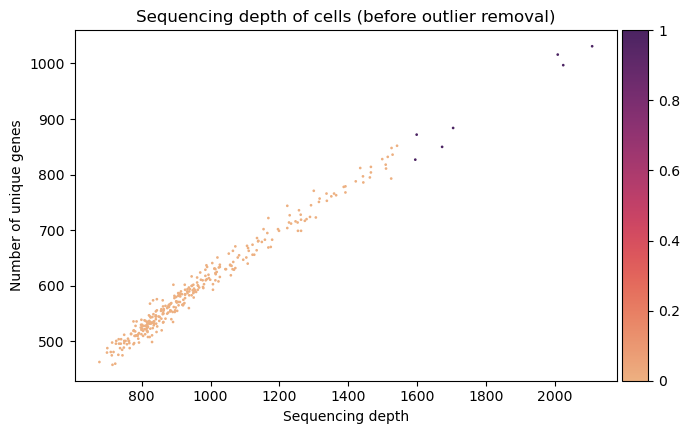

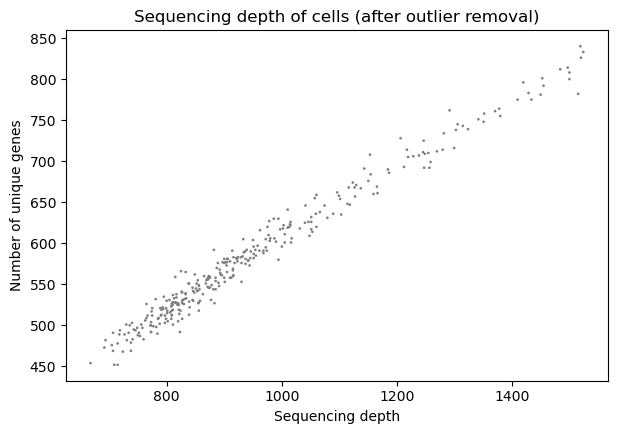

In [160]:
g = sc.pl.scatter(
    data_all,
    x="total_counts",
    y="n_genes_by_counts",
    color="outlier",
    show=False,
    size=15,
    color_map="flare",
    title="Sequencing depth of cells (before outlier removal)",
)
g.set(xlabel="Sequencing depth")
g.set(ylabel="Number of unique genes")
plt.tight_layout()
plt.show()

sc.pl.scatter(data_gene, x="total_counts", y="n_genes_by_counts", show=False, size=15)
plt.title("Sequencing depth of cells (after outlier removal)")
plt.xlabel("Sequencing depth")
plt.ylabel("Number of unique genes")
plt.show()

## Variance stabilization

Plotting the mean-variance ratio of genes, we see that the data is not overdispersed. Therefore, we will use Poisson count splitting

chaque point est un gène, l'axe des x est la moyenne des counts, l'axe des y est la variance des counts.
permet de voir si les gènes sont sur-dispersés ou pas. Si les gènes sont sur-dispersés, on utilise la méthode de variance stabilisation, sinon on utilise le Poisson count splitting

In [161]:
# Save raw counts into a layer of the anndata
data_gene.layers["counts"] = data_gene.X.copy()

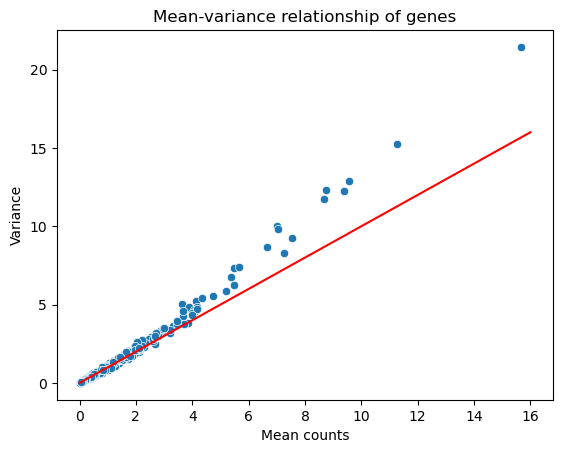

In [162]:
data_gene.var["var_counts"] = np.asarray(
    np.var(data_gene.X.toarray(), axis=0)
).squeeze()
data_gene.var["mean_counts"] = np.asarray(
    np.mean(data_gene.X.toarray(), axis=0)
).squeeze()
sns.scatterplot(data=data_gene.var, x="mean_counts", y="var_counts")
plt.plot(
    [0, np.ceil(np.max(data_gene.var["mean_counts"]))],
    [0, np.ceil(np.max(data_gene.var["mean_counts"]))],
    color="red",
)
plt.title("Mean-variance relationship of genes")
plt.xlabel("Mean counts")
plt.ylabel("Variance")
plt.show()


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).

In [163]:
# See if a linear or quadratic relationship fits better
mv_corr_lin = np.corrcoef(data_gene.var["mean_counts"], data_gene.var["var_counts"])[
    0, 1
]
mv_corr_sq = np.corrcoef(
    data_gene.var["mean_counts"] ** 2, data_gene.var["var_counts"]
)[0, 1]

if mv_corr_sq > mv_corr_lin:
    is_overdispersed = True
else:
    is_overdispersed = False

if is_overdispersed:
    print("Data is overdispersed - use Negative Binomial count splitting")
else:
    print("Data is not overdispersed - use Poisson count splitting")

Data is not overdispersed - use Poisson count splitting


## Estimate negative binomial parameters for each gene

We use scTransform to estimate the dispersion parameter for each gene, which we will use for variance stabilization

In [164]:
# Vérifier les valeurs infinies et NaN
print("Valeurs infinies:", np.isinf(data_gene.layers["counts"].toarray()).sum())
print("Valeurs NaN:", np.isnan(data_gene.layers["counts"].toarray()).sum())
print("Valeurs nulles:", (data_gene.layers["counts"].toarray() == 0).sum())

Valeurs infinies: 0
Valeurs NaN: 0
Valeurs nulles: 1182271


In [165]:
# Filtrage strict des gènes pour éviter les problèmes dans SCTransform
import numpy as np

print("=== FILTRAGE STRICT DES GÈNES ===")

# 1. Analyser les données actuelles
print(f"1. Données initiales:")
print(f"   - Forme: {data_gene.shape}")
print(f"   - Gènes: {data_gene.n_vars}")
print(f"   - Cellules: {data_gene.n_obs}")

# 2. Calculer les statistiques par gène
gene_sums = np.array(data_gene.X.sum(axis=0)).flatten()
gene_means = np.array(data_gene.X.mean(axis=0)).flatten()
gene_nonzero = np.array((data_gene.X > 0).sum(axis=0)).flatten()

print(f"\n2. Statistiques par gène:")
print(f"   - Somme min: {gene_sums.min()}")
print(f"   - Somme max: {gene_sums.max()}")
print(f"   - Somme moyenne: {gene_sums.mean():.2f}")
print(f"   - Somme médiane: {np.median(gene_sums):.2f}")

print(f"\n   - Moyenne min: {gene_means.min()}")
print(f"   - Moyenne max: {gene_means.max()}")
print(f"   - Moyenne moyenne: {gene_means.mean():.4f}")

print(f"\n   - Cellules non-nulles min: {gene_nonzero.min()}")
print(f"   - Cellules non-nulles max: {gene_nonzero.max()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero.mean():.2f}")

# 3. Définir les critères de filtrage strict
min_total_counts = 100  # Au moins 20 comptages totaux par gène
min_cells_expressed = 50  # Exprimé dans au moins 5 cellules
min_mean_expression = 0.1  # Moyenne d'expression d'au moins 0.1

print(f"\n3. Critères de filtrage:")
print(f"   - Comptages totaux minimum: {min_total_counts}")
print(f"   - Cellules exprimées minimum: {min_cells_expressed}")
print(f"   - Moyenne d'expression minimum: {min_mean_expression}")

# 4. Appliquer le filtrage
mask_total_counts = gene_sums >= min_total_counts
mask_cells_expressed = gene_nonzero >= min_cells_expressed
mask_mean_expression = gene_means >= min_mean_expression

# Combiner tous les critères
mask_combined = mask_total_counts & mask_cells_expressed & mask_mean_expression

print(f"\n4. Résultats du filtrage:")
print(f"   - Gènes passant critère comptages totaux: {mask_total_counts.sum()}")
print(f"   - Gènes passant critère cellules exprimées: {mask_cells_expressed.sum()}")
print(f"   - Gènes passant critère moyenne expression: {mask_mean_expression.sum()}")
print(f"   - Gènes passant TOUS les critères: {mask_combined.sum()}")

# 5. Créer le dataset filtré
data_gene_strict = data_gene[:, mask_combined].copy()

print(f"\n5. Dataset filtré:")
print(f"   - Forme: {data_gene_strict.shape}")
print(f"   - Gènes retenus: {data_gene_strict.n_vars}")
print(
    f"   - Pourcentage de gènes retenus: {data_gene_strict.n_vars/data_gene.n_vars*100:.1f}%"
)

# 6. Vérifier les données filtrées
gene_sums_filtered = np.array(data_gene_strict.X.sum(axis=0)).flatten()
gene_means_filtered = np.array(data_gene_strict.X.mean(axis=0)).flatten()
gene_nonzero_filtered = np.array((data_gene_strict.X > 0).sum(axis=0)).flatten()

print(f"\n6. Statistiques après filtrage:")
print(f"   - Somme min: {gene_sums_filtered.min()}")
print(f"   - Somme moyenne: {gene_sums_filtered.mean():.2f}")
print(f"   - Moyenne min: {gene_means_filtered.min()}")
print(f"   - Moyenne moyenne: {gene_means_filtered.mean():.4f}")
print(f"   - Cellules non-nulles min: {gene_nonzero_filtered.min()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero_filtered.mean():.2f}")

# 7. Vérifier qu'il n'y a plus de valeurs problématiques
print(f"\n7. Vérification des valeurs problématiques:")
X_filtered = (
    data_gene_strict.X.toarray()
    if hasattr(data_gene_strict.X, "toarray")
    else data_gene_strict.X
)
print(f"   - Valeurs NaN: {np.isnan(X_filtered).sum()}")
print(f"   - Valeurs infinies: {np.isinf(X_filtered).sum()}")
print(f"   - Valeurs négatives: {(X_filtered < 0).sum()}")

print("=== FILTRAGE TERMINÉ ===")

=== FILTRAGE STRICT DES GÈNES ===
1. Données initiales:
   - Forme: (319, 4292)
   - Gènes: 4292
   - Cellules: 319

2. Statistiques par gène:
   - Somme min: 5
   - Somme max: 4998
   - Somme moyenne: 70.78
   - Somme médiane: 21.00

   - Moyenne min: 0.01567398119122257
   - Moyenne max: 15.667711598746079
   - Moyenne moyenne: 0.2219

   - Cellules non-nulles min: 5
   - Cellules non-nulles max: 319
   - Cellules non-nulles moyenne: 43.54

3. Critères de filtrage:
   - Comptages totaux minimum: 100
   - Cellules exprimées minimum: 50
   - Moyenne d'expression minimum: 0.1

4. Résultats du filtrage:
   - Gènes passant critère comptages totaux: 608
   - Gènes passant critère cellules exprimées: 1032
   - Gènes passant critère moyenne expression: 1593
   - Gènes passant TOUS les critères: 608

5. Dataset filtré:
   - Forme: (319, 608)
   - Gènes retenus: 608
   - Pourcentage de gènes retenus: 14.2%

6. Statistiques après filtrage:
   - Somme min: 100
   - Somme moyenne: 348.44
   - Moy

In [166]:
importlib.reload(nb)
nb.estimate_overdisp_nb(
    data_gene_strict, layer="counts", flavor="sctransform", seed=5678
)

In [167]:
table = data_gene_strict.var

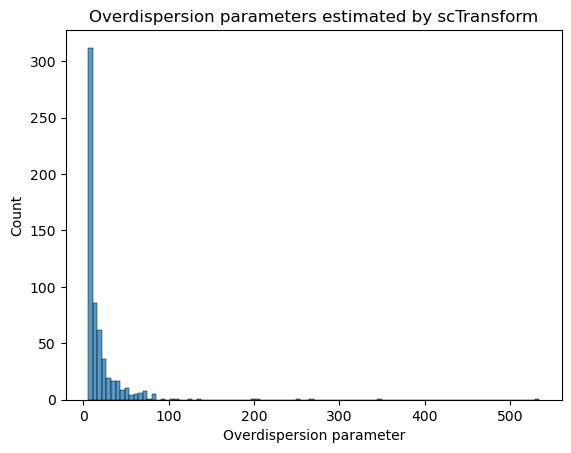

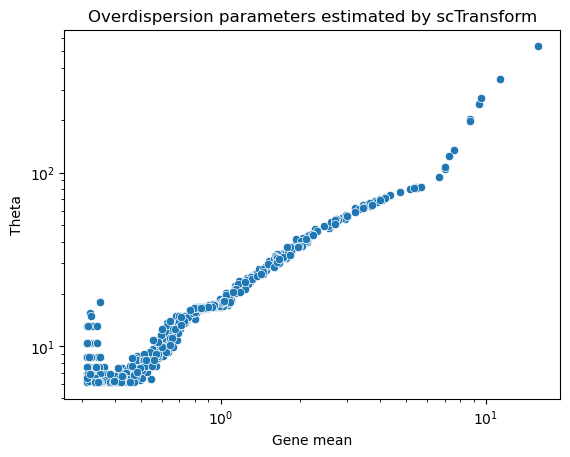

In [168]:
# Quick diagnostic plot - maybe we can spot some outlier genes here that prompt further investigation
sns.histplot(data=data_gene_strict.var, x="nb_overdisp_cutoff", bins=100)
plt.title("Overdispersion parameters estimated by scTransform")
plt.xlabel("Overdispersion parameter")
plt.show()

g = sns.scatterplot(data=data_gene_strict.var, y="nb_overdisp_cutoff", x="mean_counts")
g.set(xscale="log", yscale="log")
plt.title("Overdispersion parameters estimated by scTransform")
plt.xlabel("Gene mean")
plt.ylabel("Theta")
plt.show()

In [169]:
data_gene_strict.X = data_gene_strict.layers["counts"].copy()

## Normalization, VST, scaling and PCA

Normalize, scale and perform PCA on the data

In [125]:
sc.pp.normalize_total(data_gene_strict, target_sum=None, layer=None)
if is_overdispersed:
    data_gene_strict.X = sps.csr_matrix(
        np.log(
            data_gene_strict.X.toarray()
            + np.array(data_gene_strict.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    # data_gene_strict.X = sps.csr_matrix(np.sqrt(data_gene_strict.X.toarray()))
    data_gene_strict.X = sps.csr_matrix(
        np.log(
            data_gene_strict.X.toarray()
            + np.array(data_gene_strict.var["nb_overdisp_cutoff"] / 4)
        )
    )

data_gene_strict.layers["vst_counts"] = data_gene_strict.X.copy()
sc.pp.scale(data_gene_strict, max_value=10, zero_center=True)
sc.tl.pca(data_gene_strict, svd_solver="arpack")

Histograms of cell sequencing depths before normalization, after VST and after scaling. The data should be more centered than before

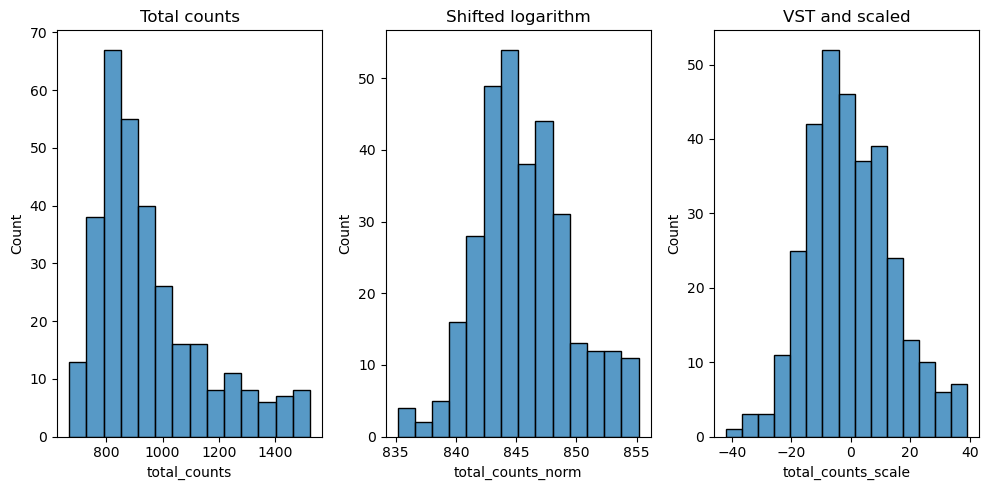

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
p1 = sns.histplot(
    data_gene_strict.obs, x="total_counts", kde=False, ax=axes[0], multiple="stack"
)
axes[0].set_title("Total counts")
data_gene_strict.obs["total_counts_norm"] = data_gene_strict.layers["vst_counts"].sum(1)
p2 = sns.histplot(
    data_gene_strict.obs, x="total_counts_norm", kde=False, ax=axes[1], multiple="stack"
)
axes[1].set_title("Shifted logarithm")
data_gene_strict.obs["total_counts_scale"] = data_gene_strict.X.sum(1)
p2 = sns.histplot(
    data_gene_strict.obs,
    x="total_counts_scale",
    kde=False,
    ax=axes[2],
    multiple="stack",
)
axes[2].set_title("VST and scaled")
plt.tight_layout()
plt.show()

## Count-splitting into train and test data

This step creates a train and test dataset, which we use to determine the latent dimensionality and clustering resolution further down the line

In [127]:
if is_overdispersed:
    data_dist = "NB"
else:
    data_dist = "Poi"
data_train, data_test = cs.countsplit_adata(
    data_gene_strict,
    data_dist=data_dist,
    beta_key="nb_overdisp_cutoff",
    layer="counts",
    min_genes=1,
    max_counts=1e9,
    seed=1234,
)
print(data_train)

AnnData object with n_obs × n_vars = 319 × 608
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group', 'outlier', 'total_counts_norm', 'total_counts_scale', 'n_counts', 'n_PCs_by_counts', 'log1p_n_PCs_by_counts'
    var: 'feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_t

Process the data in the same way as the fulld dataset (Normalize, scale, PCA)

In [128]:
sc.pp.normalize_total(data_train, target_sum=None, layer=None)
if is_overdispersed:
    data_train.X = sps.csr_matrix(
        np.log(
            data_train.X.toarray() + np.array(data_train.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    data_train.X = sps.csr_matrix(np.sqrt(data_train.X.toarray()))
data_train.layers["vst_counts"] = data_train.X.copy()
sc.pp.scale(data_train, max_value=10, zero_center=True)
sc.tl.pca(data_train, svd_solver="arpack")


sc.pp.normalize_total(data_test, target_sum=None, layer=None)
if is_overdispersed:
    data_test.X = sps.csr_matrix(
        np.log(
            data_test.X.toarray() + np.array(data_train.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    data_test.X = sps.csr_matrix(np.sqrt(data_test.X.toarray()))
data_test.layers["vst_counts"] = data_test.X.copy()
sc.pp.scale(data_test, max_value=10, zero_center=True)
sc.tl.pca(data_test, svd_solver="arpack")

In [129]:
print(type(scd))  # Doit afficher <class 'module'>
print(hasattr(scd, "scdeed_parameter_selection"))  # Doit afficher True

<class 'module'>
True


In [130]:
print(type(scd))  # Doit afficher <class 'module'>
print(hasattr(scd, "scdeed_parameter_selection"))  # Doit afficher True

<class 'module'>
True


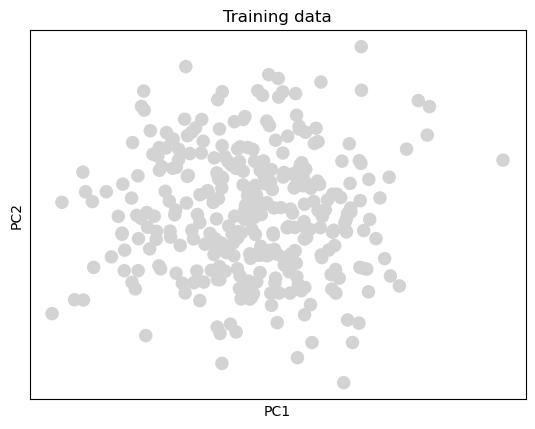

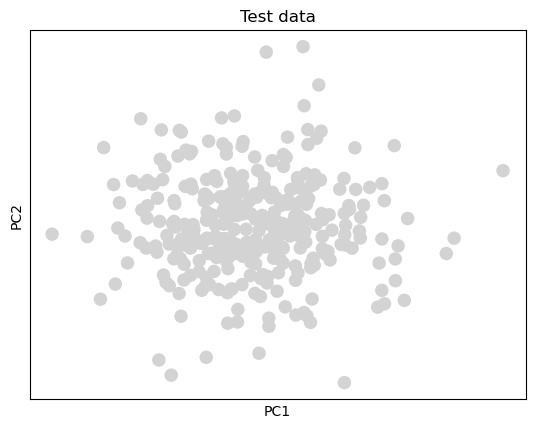

In [131]:
sc.pl.pca(data_train, title="Training data")
plt.show()

sc.pl.pca(data_test, title="Test data")
plt.show()

### Principal component selection

Select the optimal latent dimensionality k - the curve below should have a nice minimum

In [132]:
k_errors, k_opt = cs.select_n_pcs_countsplit(data_train, data_test)
print(f"Optimal number of PCs:{k_opt}")
data_gene.uns["BacSC_params"] = {"k_opt": k_opt}

Optimal number of PCs:1


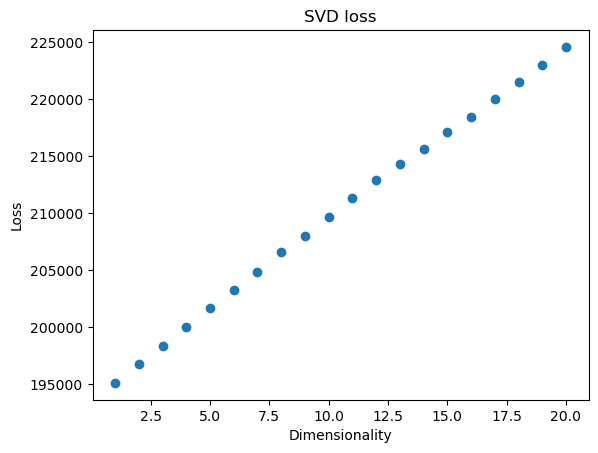

In [133]:
plt.scatter(np.arange(20) + 1, k_errors)
plt.title("SVD loss")
plt.xlabel("Dimensionality")
plt.ylabel("Loss")
plt.show()

Plot the PCA of the full dataset

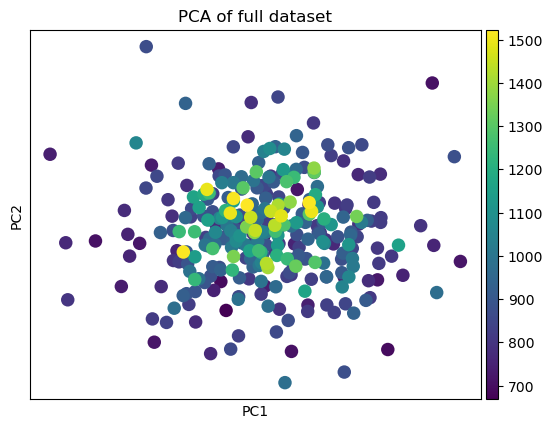

In [134]:
sc.pl.pca(
    data_gene_strict, color="total_counts", cmap="viridis", title="PCA of full dataset"
)
plt.show()

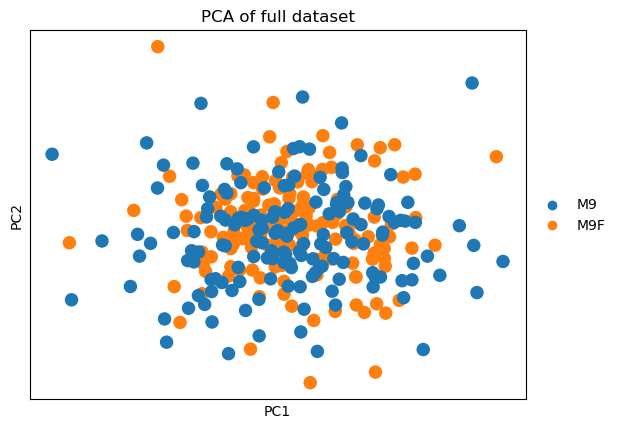

In [135]:
sc.pl.pca(
    data_gene_strict, color="CultureMedium", cmap="viridis", title="PCA of full dataset"
)

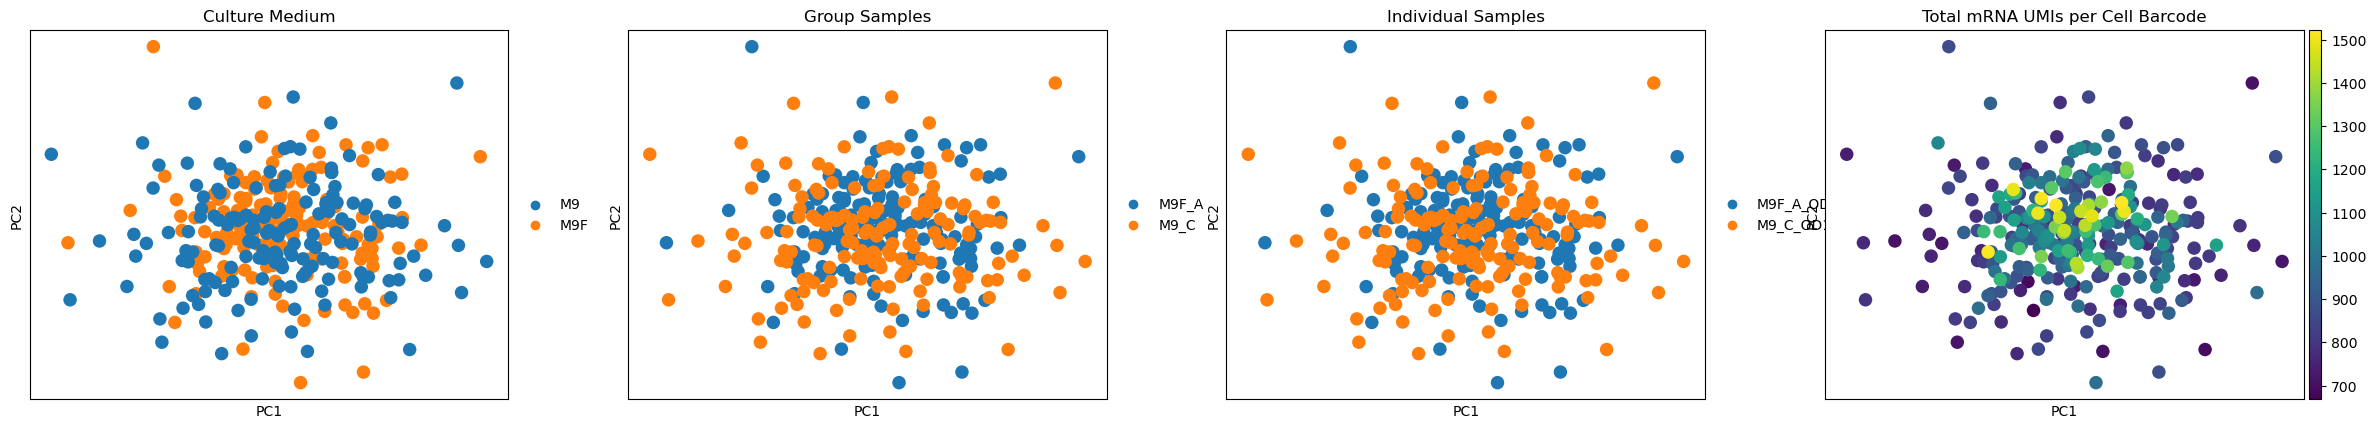

In [136]:
sc.pl.pca(
    data_gene_strict,
    color=["CultureMedium", "RepBio", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        "Group Samples",
        "Individual Samples",
        "Total mRNA UMIs per Cell Barcode",
    ],
)

## Selection of optimal number of neighbors and optimal UMAP scale via scDEED

We now select parameters for the UMAP embedding. This is done with scDEED (Xia et al., 2023). Depending on the grid of values to test, this might take a while (in this example about 30 minutes).
The results are checkpointed after each parameter set, so you can always extend your parameter range

A representative set of parameters is given below, so that this step can be skipped

In [137]:
seed = 140
print(seed)

140


In [49]:
n_neighborss = [10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 70, 80, 90, 100, 150, 200, 250]
min_dists = [0.05, 0.1, 0.3, 0.5, 0.7]

(
    scdeed_result,
    rel_scores,
    null_rel_scores,
    reliabilities,
    n_neighbors_opt,
    min_dist_opt,
) = scd.scdeed_parameter_selection(
    data_gene_strict,
    n_neighborss,
    min_dists,
    n_pcs=k_opt,
    rng_seed=seed,
    embedding_method="UMAP",
    similarity_percent=0.5,
    save_path="S3_filtered_scdeed_tutorial",
)

calculating (10, 0.05) - run 1/85
calculating (10, 0.1) - run 2/85
calculating (10, 0.3) - run 3/85
calculating (10, 0.5) - run 4/85
calculating (10, 0.7) - run 5/85
calculating (15, 0.05) - run 6/85
calculating (15, 0.1) - run 7/85
calculating (15, 0.3) - run 8/85
calculating (15, 0.5) - run 9/85
calculating (15, 0.7) - run 10/85
calculating (20, 0.05) - run 11/85
calculating (20, 0.1) - run 12/85
calculating (20, 0.3) - run 13/85
calculating (20, 0.5) - run 14/85
calculating (20, 0.7) - run 15/85
calculating (25, 0.05) - run 16/85
calculating (25, 0.1) - run 17/85
calculating (25, 0.3) - run 18/85
calculating (25, 0.5) - run 19/85
calculating (25, 0.7) - run 20/85
calculating (30, 0.05) - run 21/85
calculating (30, 0.1) - run 22/85
calculating (30, 0.3) - run 23/85
calculating (30, 0.5) - run 24/85
calculating (30, 0.7) - run 25/85
calculating (35, 0.05) - run 26/85
calculating (35, 0.1) - run 27/85
calculating (35, 0.3) - run 28/85
calculating (35, 0.5) - run 29/85
calculating (35, 

Plot the scDEED results. The plot might not exhibit a clear minimum, but we still take the parameter combination that has the least number of dubiously embedded cells

Optimal number of neighbors: 25
Optimal min_dist: 0.5


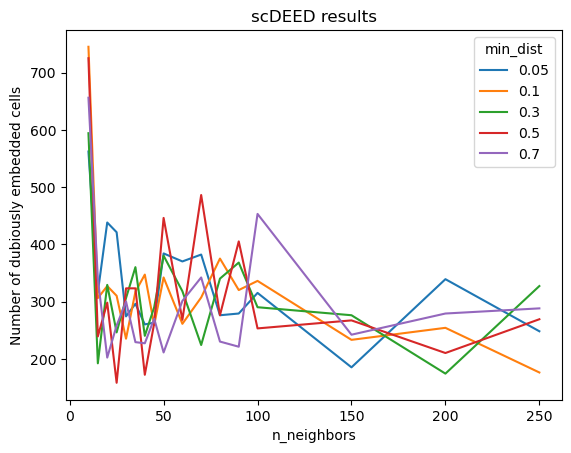

In [50]:
print(f"Optimal number of neighbors: {n_neighbors_opt}")
print(f"Optimal min_dist: {min_dist_opt}")

sns.lineplot(
    data=scdeed_result,
    x="n_neighbors",
    y="num_dubious",
    hue="min_dist",
    palette="tab10",
)
plt.title("scDEED results")
plt.ylabel("Number of dubiously embedded cells")
plt.show()

In [138]:
# Use these parameters if you don't want to run scDEED
n_neighbors_opt = 25
min_dist_opt = 0.5

In [53]:
# Save parameters to data object
data_gene_strict.uns["BacSC_params"]["n_neighbors_opt"] = n_neighbors_opt
data_gene_strict.uns["BacSC_params"]["min_dist_opt"] = min_dist_opt

KeyError: 'BacSC_params'

Compute and plot the resulting UMAP. The coloring by embedding reliability is only possible, if scDEED was performed

NOTE: UMAPs are rotation/mirroring invariant, so they might appear slightly different every time

In [139]:
sc.pp.neighbors(data_gene, n_neighbors=n_neighbors_opt, n_pcs=k_opt)
sc.tl.umap(
    data_gene,
    neighbors_key="neighbors",
    min_dist=min_dist_opt,
    spread=1,
    random_state=3456,
)

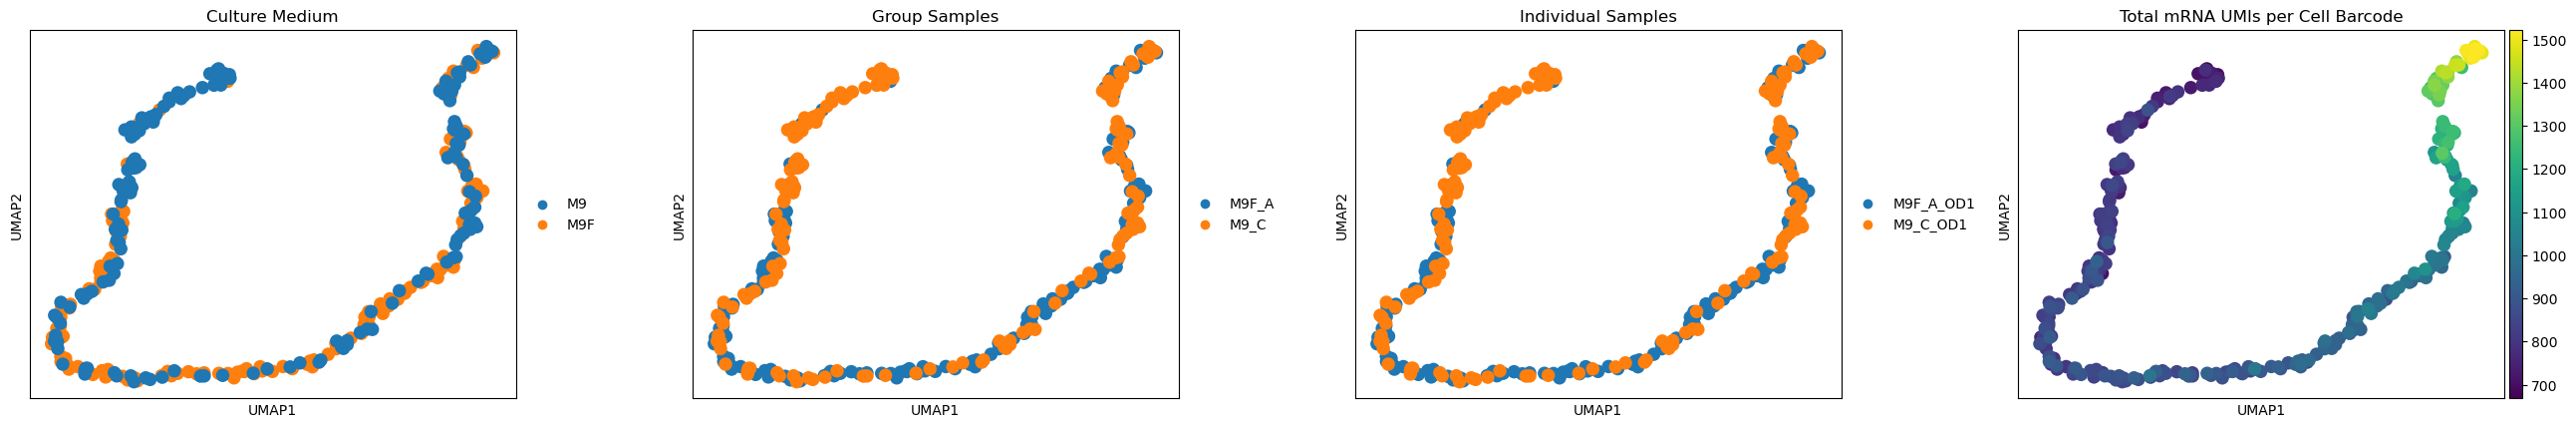

In [140]:
# sc.pl.umap(data_gene, color="embedding_reliability", alpha=1)
# plt.show()
sc.pl.umap(
    data_gene,
    color=["CultureMedium", "RepBio", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        "Group Samples",
        "Individual Samples",
        "Total mRNA UMIs per Cell Barcode",
    ],
    wspace=0.24,  # Increase space between plots horizontally
    hspace=0.3,  # Increase space between plots vertically
)
plt.show()

In [ ]:
print(type(scd))  # Doit afficher <class 'module'>
print(hasattr(scd, "scdeed_parameter_selection"))  # Doit afficher True

=== DIAGNOSTIC DES BIAIS DE PROFONDEUR ===


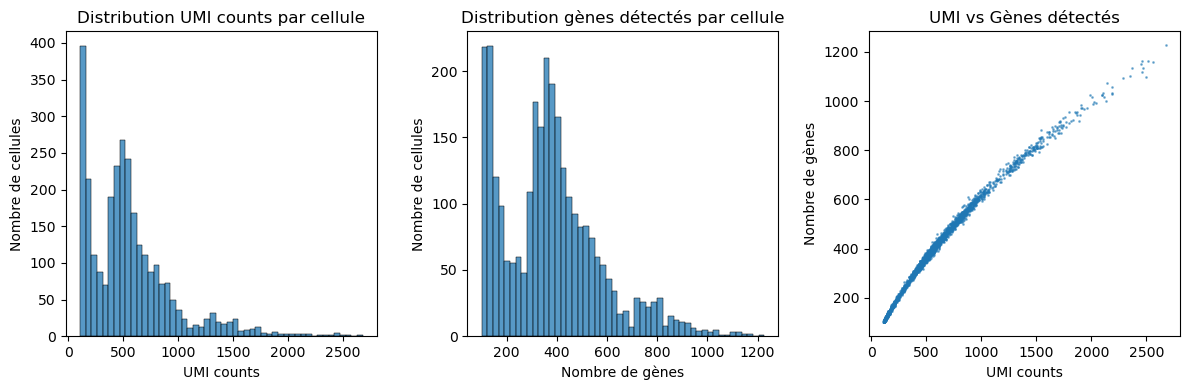


📊 Statistiques de profondeur:
   - UMI counts - Min: 108, Max: 2677
   - UMI counts - Moyenne: 560.7, Médiane: 498.0
   - Ratio Max/Min UMI: 24.8
   - Gènes détectés - Min: 100, Max: 1227
   - Gènes détectés - Moyenne: 376.6, Médiane: 362.0


In [46]:
# Diagnostic des biais de profondeur
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("=== DIAGNOSTIC DES BIAIS DE PROFONDEUR ===")

# 1. Distribution des UMI counts par cellule
umi_counts = np.array(data_gene.X.sum(axis=1)).flatten()
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(umi_counts, bins=50)
plt.title("Distribution UMI counts par cellule")
plt.xlabel("UMI counts")
plt.ylabel("Nombre de cellules")

# 2. Distribution des gènes détectés par cellule
genes_detected = np.array((data_gene.X > 0).sum(axis=1)).flatten()
plt.subplot(1, 3, 2)
sns.histplot(genes_detected, bins=50)
plt.title("Distribution gènes détectés par cellule")
plt.xlabel("Nombre de gènes")
plt.ylabel("Nombre de cellules")

# 3. Relation UMI vs gènes détectés
plt.subplot(1, 3, 3)
plt.scatter(umi_counts, genes_detected, alpha=0.5, s=1)
plt.title("UMI vs Gènes détectés")
plt.xlabel("UMI counts")
plt.ylabel("Nombre de gènes")

plt.tight_layout()
plt.show()

# Statistiques
print(f"\n📊 Statistiques de profondeur:")
print(f"   - UMI counts - Min: {umi_counts.min()}, Max: {umi_counts.max()}")
print(
    f"   - UMI counts - Moyenne: {umi_counts.mean():.1f}, Médiane: {np.median(umi_counts):.1f}"
)
print(f"   - Ratio Max/Min UMI: {umi_counts.max()/umi_counts.min():.1f}")
print(f"   - Gènes détectés - Min: {genes_detected.min()}, Max: {genes_detected.max()}")
print(
    f"   - Gènes détectés - Moyenne: {genes_detected.mean():.1f}, Médiane: {np.median(genes_detected):.1f}"
)

**Checkpoint** 

Save the data to disk and read it again

In [ ]:
data_gene.write(data_path + "/filtered_data_maxpool_processed_tutorial.h5ad")

In [ ]:
data_gene = sc.read_h5ad(data_path + "/filtered_data_maxpool_processed_tutorial.h5ad")
data_gene

## Clustering

We now apply Leiden clustering to the data. For this, we need to find a resolution parameter that points out the clusters in the data well

### Train/test-split for clustering

We apply the UMAP embedding with the previously calculated parameters to the train and test data.

In [ ]:
k_opt = data_gene.uns["BacSC_params"]["k_opt"]
n_neighbors_opt = data_gene.uns["BacSC_params"]["n_neighbors_opt"]
min_dist_opt = data_gene.uns["BacSC_params"]["min_dist_opt"]

sc.pp.neighbors(data_train, n_neighbors=n_neighbors_opt, n_pcs=k_opt)
sc.tl.umap(
    data_train,
    neighbors_key="neighbors",
    min_dist=min_dist_opt,
    spread=1,
    random_state=1234,
)

sc.pp.neighbors(data_test, n_neighbors=n_neighbors_opt, n_pcs=k_opt)
sc.tl.umap(
    data_test,
    neighbors_key="neighbors",
    min_dist=min_dist_opt,
    spread=1,
    random_state=1234,
)


theta_opt, mirror_opt, umap_2_opt, ssd = ut.find_opt_umap_rotation(
    data_train.obsm["X_umap"].copy(), data_test.obsm["X_umap"].copy()
)
data_test.obsm["X_umap_rot"] = umap_2_opt

In [ ]:
sc.pl.umap(data_train, color="total_counts", cmap="viridis", title="Training data")
plt.show()

sc.pl.embedding(
    data_test,
    basis="X_umap_rot",
    color="total_counts",
    cmap="viridis",
    title="Test data",
)
plt.show()

### Apply clustering with array of resolutions

This step might also take a few minutes, based on the size of the data. You can also adjust the range of considered resolutions

In [ ]:
res_min = 0.01
res_max = 0.5
res_step = 0.02
resolutions = np.round(np.arange(res_min, res_max, res_step), 2)
print(f"Resolutions to test: {resolutions}")

# 234
co.cluster_train_test(
    data_train, data_test, resolutions, alg="leiden", random_state=234
)

In [ ]:
for resolution in resolutions:
    fig, ax = plt.subplots(1, 2, figsize=(8, 3))
    sc.pl.umap(
        data_train,
        color=f"leiden_res{resolution}",
        ax=ax[0],
        title=f"Train data, resolution {resolution}",
        show=False,
    )
    sc.pl.embedding(
        data_test,
        basis="X_umap_rot",
        color=f"leiden_res{resolution}",
        ax=ax[1],
        title=f"Test data, resolution {resolution}",
        show=False,
    )
    ax[1].set_xlabel("UMAP1")
    ax[1].set_ylabel("UMAP2")
    plt.tight_layout()
    plt.show()

Compute modularities on train data for each clustering and select resolution with biggest increase in resolution on train data over a random clustering

In [ ]:
mod_df, mod_df_wide, res_opt = co.find_optimal_clustering_resolution(
    data_train, data_test, resolutions, random_seed=1234
)

print(f"Optimal resolution {res_opt}")

In [ ]:
sns.lineplot(data=mod_df, x="resolution", y="score", hue="type")
plt.title("Clustering modularities")
plt.xlabel("Resolution")
plt.ylabel("Modularity")
plt.show()

sns.lineplot(data=mod_df_wide, x="resolution", y="diff_rand_test")
plt.title("Clustering modularities")
plt.xlabel("Resolution")
plt.ylabel("Difference Test-Random")
plt.show()

In [ ]:
# Checkpoint value for resolution to reduce computation time
res_opt = 0.23
data_gene.uns["BacSC_params"]["res_opt"] = res_opt

### Apply clustering to full dataset

In [ ]:
sc.tl.leiden(data_gene, resolution=res_opt, key_added="leiden_opt", random_state=1234)

In [ ]:
sc.pl.umap(data_gene, color="leiden_opt", palette="tab10", title="Sample 3")
plt.show()

In [ ]:
sc.pl.scatter(
    data_gene,
    x="total_counts",
    y="n_genes_by_counts",
    show=False,
    size=15,
    color="leiden_opt",
)
plt.title("Sequencing depth of cells (after outlier removal)")
plt.xlabel("Sequencing depth")
plt.ylabel("Number of unique genes")
plt.show()

**Checkpoint**

Save the data to disk and read it again

In [ ]:
data_gene.write(data_path + "/filtered_data_maxpool_processed_tutorial.h5ad")

## Attach feature table

In [ ]:
data_gene = sc.read_h5ad(data_path + "/filtered_data_maxpool_processed_tutorial.h5ad")
data_gene

In [ ]:
# Adjust the path to the feature table
feature_table = pd.read_csv(
    "../data/MOBA_scRNAseq/P_aeruginosa_PAO1_feature_table.tsv", sep="\t"
)
feature_table = feature_table[["Locus tag", "Protein accession", "Name", "Symbol"]]
feature_table["Locus tag"] = [str(x) for x in feature_table["Locus tag"]]
feature_table

In [ ]:
df3 = (
    data_gene.var.reset_index()
    .merge(feature_table, how="left", left_on="index", right_on="Symbol")
    .drop_duplicates("index")
    .set_index("index")
)
data_gene.var = df3
data_gene.var

Save final dataset

In [ ]:
data_gene.write(data_path + "/filtered_data_maxpool_processed_tutorial.h5ad")

This concludes the main BacSC pipeline. To perform differential expression analysis, continue with the clustering analysis tutorial.